# Лабораторна робота №3. Обробка відео
### «Методи обробки мультимедійної інформації» — Ходаков Максим Олегович, ОНП «Штучний інтелект»

**Завдання.** Для відео тривалістю 30–60 с, що містить автомобіль, його номер, обличчя водія біля автомобіля,
додаткові об'єкти та **один рухомий об'єкт**, розробити елементи ПЗ, які:

1. виділяють об'єкти у фільмі й розпізнають їх (автомобіль, номер, люди, тварина);
2. за допомогою відомої мережі знаходять і **читають номер автомобіля**;
3. **ідентифікують водія**.

Відео — синтетичне (дозволено викладачем): сцена зібрана з вільних фотографій, причому вона **відрізняється від
демонстраційної**: інший автомобіль (ЗАЗ Sens, вид спереду, шкільне подвір'я), власний номер `KA 7429 MB`,
інший водій та еталонне фото, пасажир з іншого джерела, собака і другий автомобіль як додаткові об'єкти,
тривалість 40 с (а не 10 с), камера «з руки» з наближенням і панорамою.

| Задача | Модель / метод |
|---|---|
| об'єкти | **YOLO11m** (Ultralytics), навчена на COCO (80 класів) |
| відстеження | **ByteTrack** (вбудований в Ultralytics) |
| рух камери | оптичний потік Лукаса–Канаде + RANSAC (перетворення подібності) |
| номерний знак | **YOLOv11s**, донавчена на номерних знаках (`morsetechlab/yolov11-license-plate-detection`) |
| символи номера | **EasyOCR** (детектор тексту CRAFT + розпізнавач CRNN) + шаблон `LLDDDDLL` + голосування |
| обличчя | **YuNet** (детектор) + **SFace** (128-вимірний вектор-ознака), OpenCV Zoo |

Код конвеєра — у пакеті `src/lab3/` (кожен модуль детально задокументований); ноутбук запускає кроки по черзі
та показує проміжні результати.

In [1]:
import sys, json, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import cv2, numpy as np, pandas as pd, torch, ultralytics, easyocr
import matplotlib.pyplot as plt
from IPython.display import Image, HTML, display

from lab3 import config as C
from lab3.scene import build_scene
from lab3.pipeline import run_pipeline
from lab3.plates import normalize_plate
from lab3.faces import FaceIdentifier

print("Python", sys.version.split()[0], "| torch", torch.__version__, "| ultralytics", ultralytics.__version__,
      "| OpenCV", cv2.__version__, "| EasyOCR", easyocr.__version__)
print("Пристрій для нейромереж:", C.DEVICE, "| MPS доступний:", torch.backends.mps.is_available())
for p in [C.COCO_MODEL, C.SEG_MODEL, C.PLATE_MODEL, C.YUNET_MODEL, C.SFACE_MODEL]:
    print(f"  {p.name:42s} {p.stat().st_size / 1e6:6.1f} МБ")

Python 3.14.2 | torch 2.14.1 | ultralytics 8.4.183 | OpenCV 5.0.0 | EasyOCR 1.7.2
Пристрій для нейромереж: mps | MPS доступний: True
  yolo11m.pt                                   40.7 МБ
  yolo11m-seg.pt                               45.4 МБ
  license-plate-finetune-v1s.pt                19.2 МБ
  face_detection_yunet_2023mar.onnx             0.2 МБ
  face_recognition_sface_2021dec.onnx          38.7 МБ


## 1. Відео

Сцену будує модуль `lab3.scene`:

* **фон і головний автомобіль** — фото ЗАЗ Sens (Wikimedia Commons, автор Вальдимар, CC BY-SA 3.0); на місце
  зачорненого номера нанесено власний знак `KA 7429 MB`, намальований за пропорціями ДСТУ 4278:2019 (520×112 мм,
  синя смуга з прапором і «UA») і перенесений гомографією (перспективне перетворення);
* **водій** — людина з фото 2012 р. (UNICEF Ukraine, CC BY 2.0), стоїть біля авто ближче до камери;
* **пасажир** — людина з тестового фото Ultralytics `bus.jpg`; іде зліва направо — **єдиний рухомий об'єкт**;
* **додатковий об'єкт** — собака (цуценя, CC0); у кадрі також є **другий автомобіль** (синій, ліворуч).

Людей і собаку вирізано сегментаційною мережею **YOLO11m-seg** (маска екземпляра → альфа-канал), кольори
вирівняні до фону переносом статистики в просторі L\*a\*b\*. Віртуальна камера: наближення 1.0→1.35→1.0,
панорама, тремтіння рук (сума синусоїд), поворот ±0.35°, шум сенсора, H.264 8 Мбіт/с.

Оскільки сцена згенерована, для кожного кадру збережено **еталонну розмітку** (рамки, видимість, рух камери).

In [2]:
REBUILD_SCENE = not C.SCENE_VIDEO.exists()   # True — перегенерувати відео
if REBUILD_SCENE:
    t0 = time.time()
    build_scene(preview_dir=C.FIGURES_DIR)
    print(f"Сцену згенеровано за {time.time() - t0:.0f} с")

gt = json.loads(C.SCENE_GT.read_text())
cap = cv2.VideoCapture(str(C.SCENE_VIDEO))
print(f"{C.SCENE_VIDEO.name}: {int(cap.get(3))}×{int(cap.get(4))}, {cap.get(5):.0f} кадр/с, "
      f"{int(cap.get(7))} кадрів = {cap.get(7) / cap.get(5):.1f} с, {C.SCENE_VIDEO.stat().st_size / 1e6:.1f} МБ")

frames = []
for f in (0, 250, 450, 900):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f); ok, fr = cap.read(); frames.append((f, fr))
cap.release()
fig, axes = plt.subplots(2, 2, figsize=(13, 7.4))
for ax, (f, fr) in zip(axes.ravel(), frames):
    ax.imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)); ax.set_title(f"кадр {f} (t = {f / 25:.0f} с)"); ax.axis("off")
plt.tight_layout(); plt.show()

synthetic_scene.mp4: 1280×720, 25 кадр/с, 1000 кадрів = 40.0 с, 40.0 МБ


/var/folders/1v/0nk9v_mn4ln_2xhmvqccfwj40000gn/T/ipykernel_83545/3009773134.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


In [3]:
# Еталонна розмітка для одного кадру: видимі рамки об'єктів і частка видимих пікселів
pd.DataFrame(gt["frames_gt"][300]["objects"])

,name,cls,box,visibility
0,car_second,car,"[2.2, 66.5, 250.7, 391.8]",0.338
1,car_main,car,"[69.0, 4.3, 1144.5, 678.0]",0.845
2,plate,plate,"[271.3, 404.3, 437.9, 470.9]",0.594
3,dog,dog,"[48.7, 578.6, 281.8, 704.1]",0.319
4,passenger,person,"[112.6, 84.2, 289.2, 719.5]",0.973
5,driver,person,"[970.7, 134.7, 1278.2, 718.8]",0.601


## 2. Еталонне фото водія

Для ідентифікації потрібне **окреме** фото водія, а не кадр з відео. Використано фото 2016 р. (Oleg Dubyna,
CC BY-SA 2.0): інший рік, одяг, освітлення та ракурс. YuNet знаходить обличчя та 5 ключових точок, обличчя
вирівнюється до 112×112 і SFace перетворює його на вектор зі 128 чисел. Дві фотографії вважаються однією
людиною, якщо косинусна схожість векторів **> 0.363** (поріг авторів моделі).

In [4]:
fi = FaceIdentifier()
fi.set_reference(C.DRIVER_REFERENCE)
ref = cv2.imread(str(C.DRIVER_REFERENCE))
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [3, 1]})
a.imshow(cv2.cvtColor(ref, cv2.COLOR_BGR2RGB)); a.set_title("еталонне фото водія (2016)"); a.axis("off")
b.imshow(cv2.cvtColor(fi.reference_face, cv2.COLOR_BGR2RGB)); b.set_title("вирівняне обличчя 112×112"); b.axis("off")
plt.show()
print("Довжина вектора SFace:", fi.reference.shape[1])

[ WARN:0@3.203] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@3.232] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


Довжина вектора SFace: 128


/var/folders/1v/0nk9v_mn4ln_2xhmvqccfwj40000gn/T/ipykernel_83545/313219449.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 3. Обробка відео кадр за кадром

`run_pipeline` (модуль `lab3.pipeline`) для кожного кадру:

* `ObjectTracker.update` — YOLO11m знаходить об'єкти потрібних класів, ByteTrack присвоює їм постійні номери;
* `CameraMotionEstimator.update` — кутові точки фону (поза рамками об'єктів) відстежуються оптичним потоком,
  RANSAC оцінює зсув/масштаб/поворот кадру; добуток перетворень дає відображення «кадр → перший кадр»;
* кожен 2-й кадр: `PlateReader.read` (детектор номерів → збільшення ×3, CLAHE → EasyOCR → шаблон) і
  `FaceIdentifier.process` (YuNet → SFace → схожість з еталоном).

Потім `analysis.summarize` агрегує все по треках, `annotate.write_annotated` малює анотоване відео,
`evaluation.evaluate` порівнює результати з еталонною розміткою.

In [5]:
REUSE_CACHE = False   # True — взяти результати нейромереж з data/records.pkl (лише перерахувати аналіз)
out = run_pipeline(C.SCENE_VIDEO, C.DRIVER_REFERENCE, reuse=REUSE_CACHE)
records, summary, result = out["records"], out["summary"], out["result"]

Обробка /Users/maksymkhodakov/PycharmProjects/MultimediaDataLab34/data/synthetic_scene.mp4 ...


/Users/maksymkhodakov/PycharmProjects/MultimediaDataLab34/.venv/lib/python3.14/site-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:116.)
  w_ih = torch.quantize_per_tensor(
[ WARN:0@5.602] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@5.626] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


/Users/maksymkhodakov/PycharmProjects/MultimediaDataLab34/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


  оброблено 100/1000 кадрів (3.8 кадр/с)


  оброблено 200/1000 кадрів (3.9 кадр/с)


...

  оброблено 900/1000 кадрів (3.3 кадр/с)


  оброблено 1000/1000 кадрів (3.3 кадр/с)
Оброблено 1000 кадрів за 301 с (3.3 кадр/с)


/Users/maksymkhodakov/PycharmProjects/MultimediaDataLab34/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


[ WARN:0@325.153] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@325.228] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


Ілюстрації: fig_pipeline.png, fig_confidence.png, fig_similarity.png, fig_movement.png, fig_trajectory.png, fig_plate_examples.png, fig_faces.png, fig_camera.png

ПІДСУМОК ОБРОБКИ ВІДЕО synthetic_scene.mp4
----------------------------------------------------------------------
Треків всього: 13, об'єднано фрагментів: {18: 1}, частини інших об'єктів: [9], крайові: [9, 10, 19, 26], залишилось: 5
трек клас     кадрів впевн.   рух*  наїв.1  наїв.2 рухається  схожість з водієм      роль
   1 car        1000   0.95   0.02    0.00    0.22        ні  -                      автомобіль з номером KA7429MB
   2 person     1000   0.94   0.06    0.00    0.18        ні  0.707 (у 498 кадрах)   ВОДІЙ
   3 dog         994   0.92   0.03    0.01    1.13        ні  -                      додатковий об'єкт
   4 car         989   0.83   0.02    0.01    0.58        ні  -                      інший автомобіль
   5 person      511   0.89   1.42   13.26   13.26       так  0.115 (у 241 кадрах)   інша людина (пасаж

## 4. Аналіз результатів

### 4.1. Об'єкти та рухомий об'єкт
Треки, коротші за 10 % відео, відкинуто як шум; фрагменти одного нерухомого об'єкта (зміна номера треку під
час наближення камери) об'єднано; «крайові» треки з низькою впевненістю (частина руки водія біля краю кадру)
відкинуто. Рух оцінюється **після компенсації руху камери**: розмах положень сторін рамки в координатах першого
кадру, поділений на розмір об'єкта; поріг — 0.25.

In [6]:
rows = [{"трек": t.track_id, "клас": t.cls, "кадрів": t.n_frames, "впевненість": round(t.mean_conf, 3),
         "рух (компенс.)": round(t.move_score, 3), "рух (демо: перша→остання)": round(t.move_score_naive, 3),
         "рух (макс. без компенс.)": round(t.move_score_naive_max, 3), "рухається": "так" if t.moving else "ні",
         "схожість з водієм": None if t.mean_similarity is None else round(t.mean_similarity, 3),
         "облич": t.face_samples, "роль": t.role} for t in summary["tracks"]]
print("Об'єднані фрагменти:", summary["merged_tracks"], "| частини інших об'єктів:", summary["part_tracks"],
      "| крайові:", summary["edge_tracks"])
pd.DataFrame(rows)

Об'єднані фрагменти: {18: 1} | частини інших об'єктів: [9] | крайові: [9, 10, 19, 26]


,трек,клас,кадрів,впевненість,рух (компенс.),рух (демо: перша→остання),рух (макс. без компенс.),рухається,схожість з водієм,облич,роль
0,1,car,1000,0.946,0.016,0.003,0.223,ні,NaN,0,автомобіль з номером KA7429MB
1,2,person,1000,0.938,0.063,0.001,0.185,ні,0.707,498,ВОДІЙ
2,3,dog,994,0.916,0.026,0.014,1.134,ні,NaN,0,додатковий об'єкт
3,4,car,989,0.826,0.020,0.014,0.581,ні,NaN,0,інший автомобіль
4,5,person,511,0.887,1.422,13.257,13.257,так,0.115,241,інша людина (пасажир)


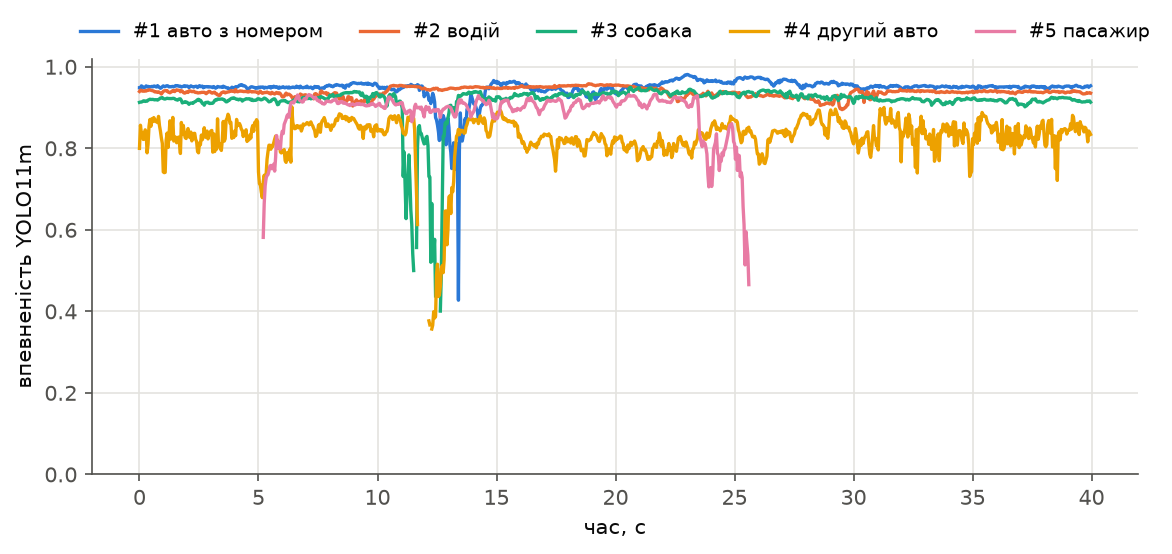

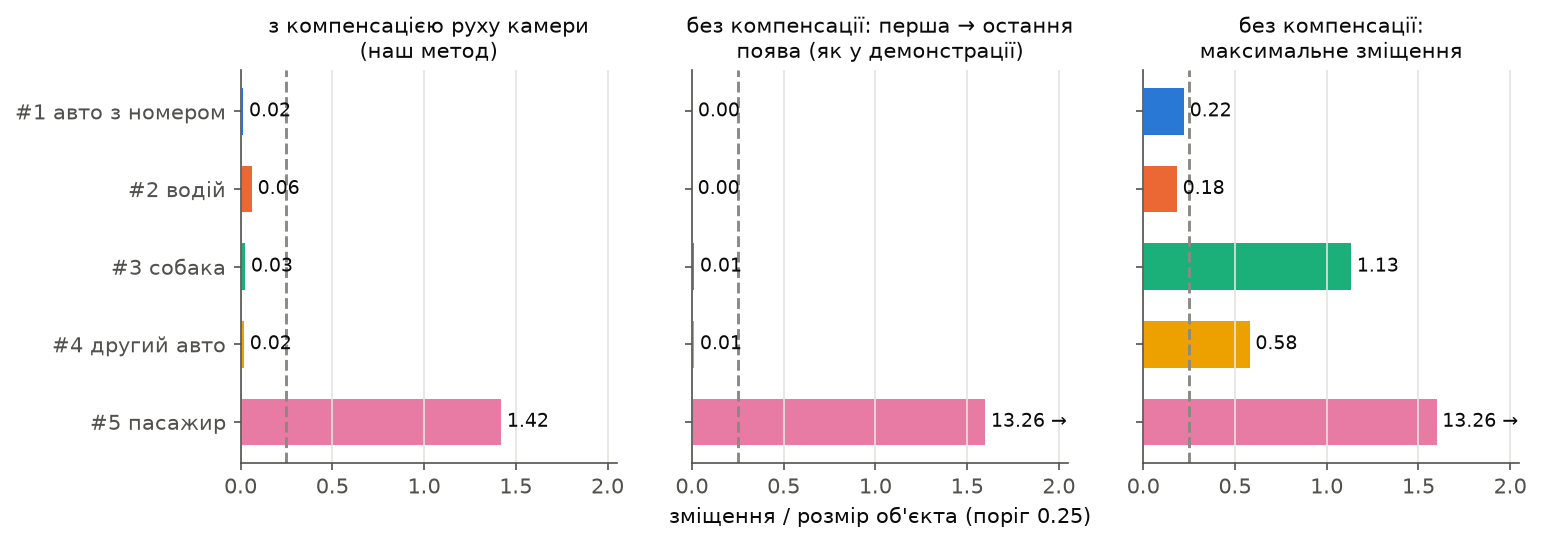

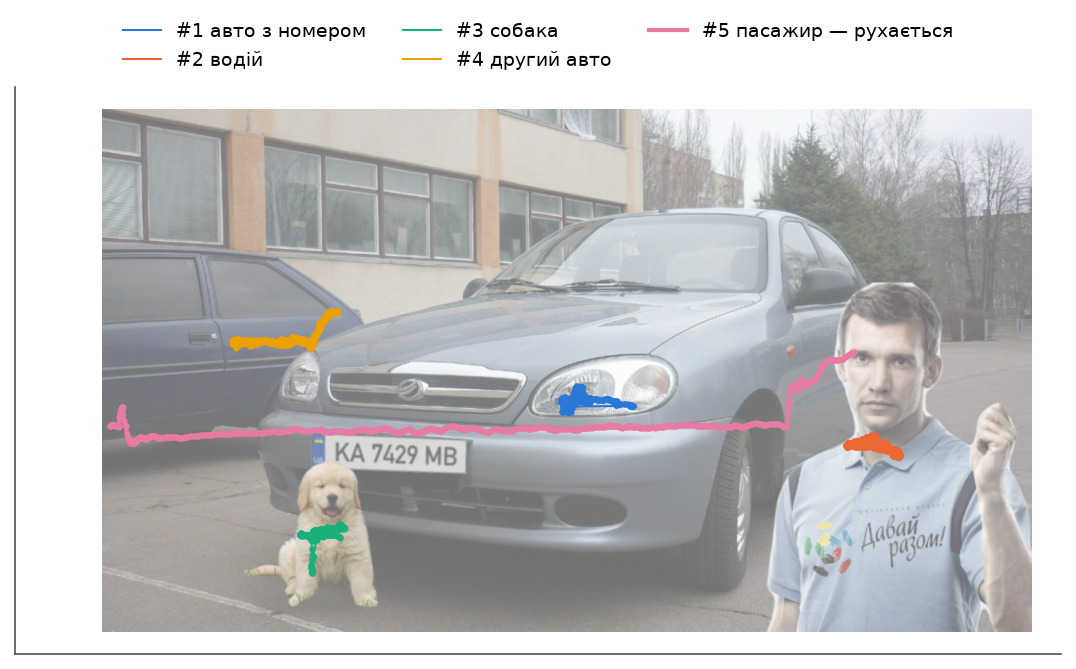

In [7]:
display(Image(str(C.FIGURES_DIR / "fig_confidence.png")))
display(Image(str(C.FIGURES_DIR / "fig_movement.png")))
display(Image(str(C.FIGURES_DIR / "fig_trajectory.png")))

Без компенсації руху камери метрика «максимальне зміщення» помилково вважає рухомими собаку й другий
автомобіль (через наближення камери вони зміщуються в кадрі на розмір, більший за власний). Метрика з
демонстрації (перша → остання поява) тут дає правильну відповідь лише тому, що камера в кінці повертається
у вихідне положення. Оцінка руху камери перевірена за еталоном:

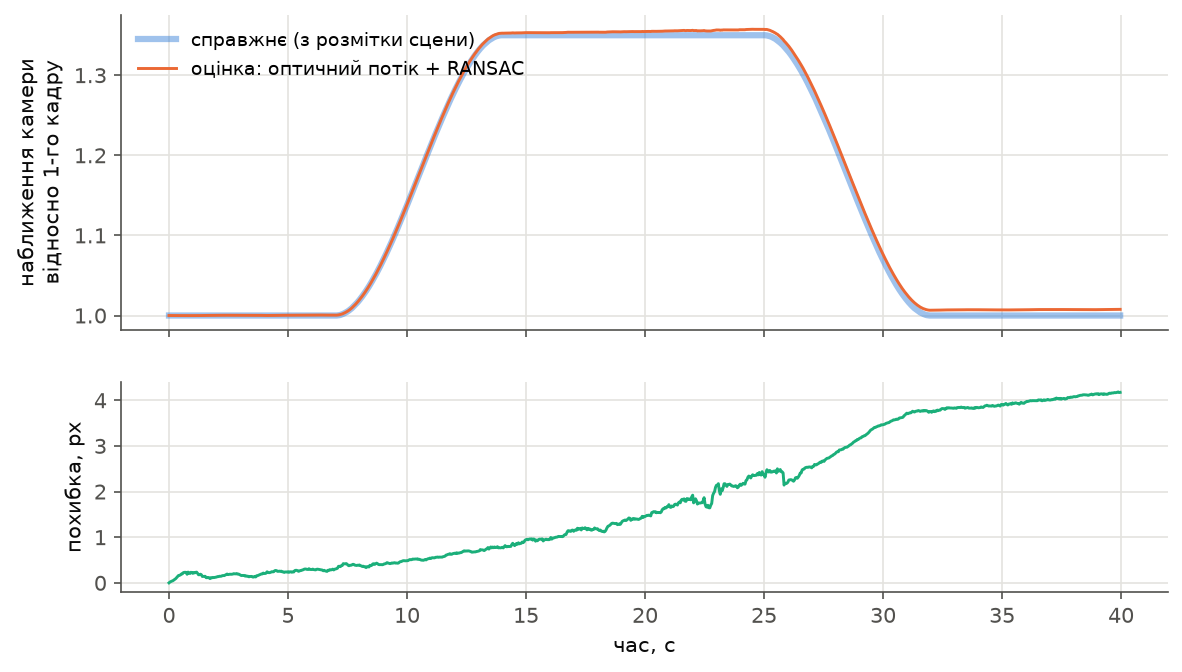

Похибка перенесення точок у систему 1-го кадру: середня 1.85 px, максимальна 4.18 px (накопичується повільно, ~0.1 px/с)


In [8]:
display(Image(str(C.FIGURES_DIR / "fig_camera.png")))
cam = result["evaluation"]["camera"]
print(f"Похибка перенесення точок у систему 1-го кадру: середня {cam['mean_error_px']} px, "
      f"максимальна {cam['max_error_px']} px (накопичується повільно, ~0.1 px/с)")

### 4.2. Номерний знак
OCR повертає сирий рядок, де бувають зайві символи («UA» з синьої смуги) та сплутані O/0, I/1, B/8.
`normalize_plate` шукає вікно з 8 символів, яке після мінімуму виправлень (з урахуванням позиції: літери на
місцях 1–2, 7–8, цифри на 3–6) відповідає українському шаблону; більше двох виправлень — читання відкидається.

In [9]:
for raw in ["UA KA7429MB", "KA 7A29 M8", "0A KA 7429 MB", "KA7429ME", "7429MB", "KA 1429 MBB"]:
    print(f"{raw!r:18} -> {normalize_plate(raw)}")

'UA KA7429MB'      -> ('KA7429MB', 0)
'KA 7A29 M8'       -> ('KA7429MB', 2)
'0A KA 7429 MB'    -> ('KA7429MB', 0)
'KA7429ME'         -> ('KA7429ME', 0)
'7429MB'           -> (None, 99)
'KA 1429 MBB'      -> ('KA1429MB', 0)


Кадрів, де знайдено знак: 496 | з валідним форматом: 440
Голосування за рядком: {'KA7429MB': 438, 'KA7429ME': 2} -> KA7429MB
Посимвольне голосування: KA7429MB
НОМЕР АВТОМОБІЛЯ: KA7429MB | належить треку авто # 1


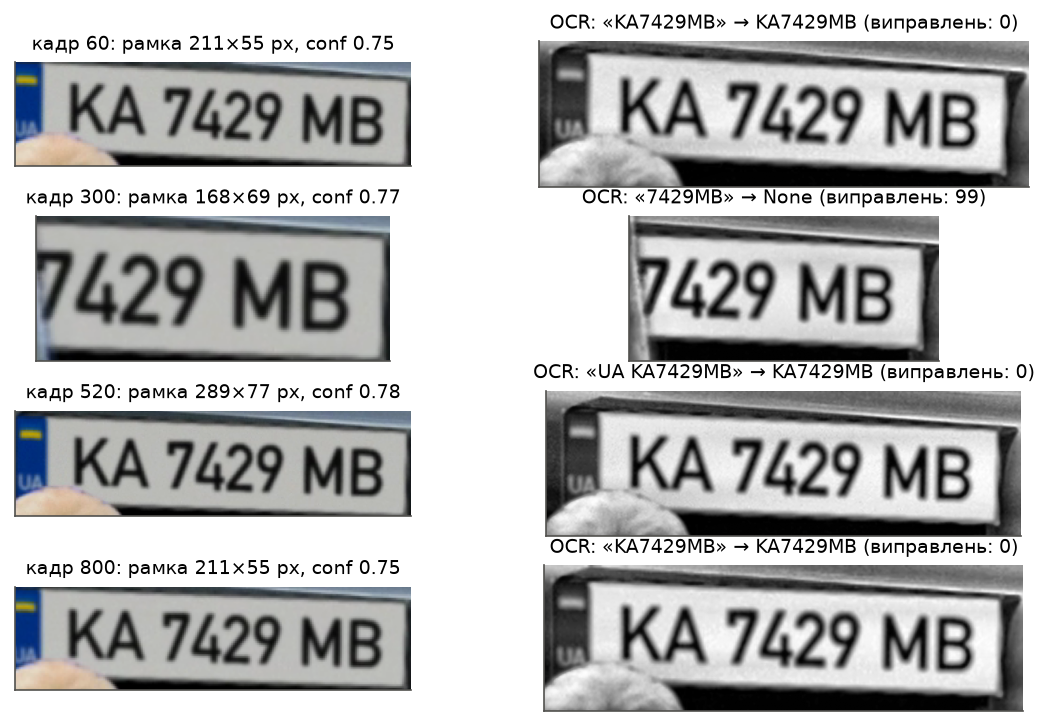

In [10]:
p = summary["plate"]
print("Кадрів, де знайдено знак:", p["frames_with_plate"], "| з валідним форматом:", p["valid_reads"])
print("Голосування за рядком:", p["counts"], "->", p["by_string"])
print("Посимвольне голосування:", p["by_char"])
print("НОМЕР АВТОМОБІЛЯ:", summary["plate_text"], "| належить треку авто #", summary["plate_car_id"])
display(Image(str(C.FIGURES_DIR / "fig_plate_examples.png")))

### 4.3. Ідентифікація водія
Кожне знайдене обличчя прив'язується до найменшої рамки `person`, у яку потрапляє його центр. Водій — трек,
середня схожість облич якого з еталоном найбільша й перевищує поріг 0.363.

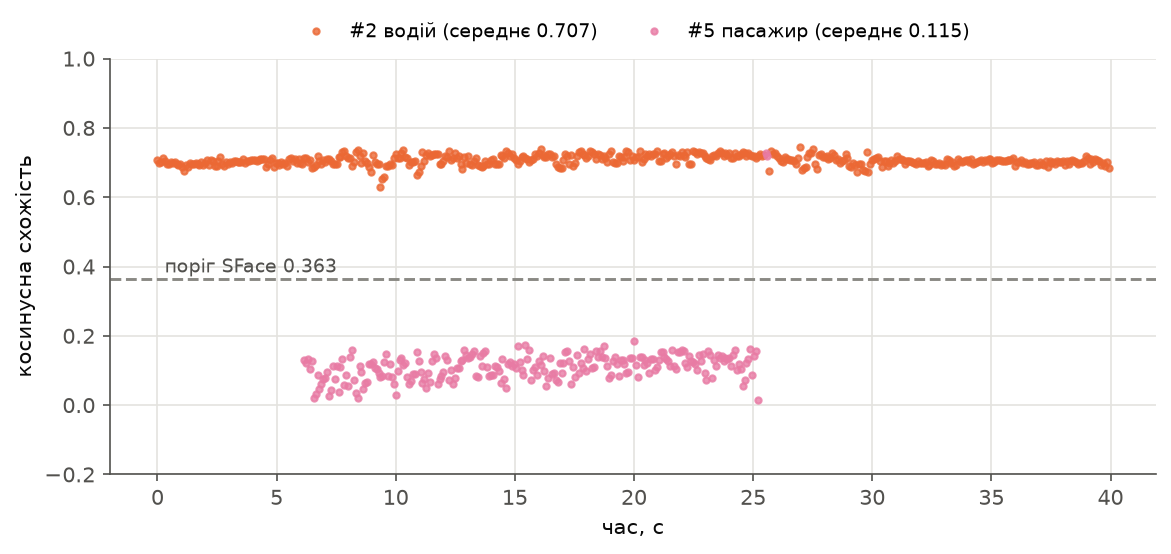

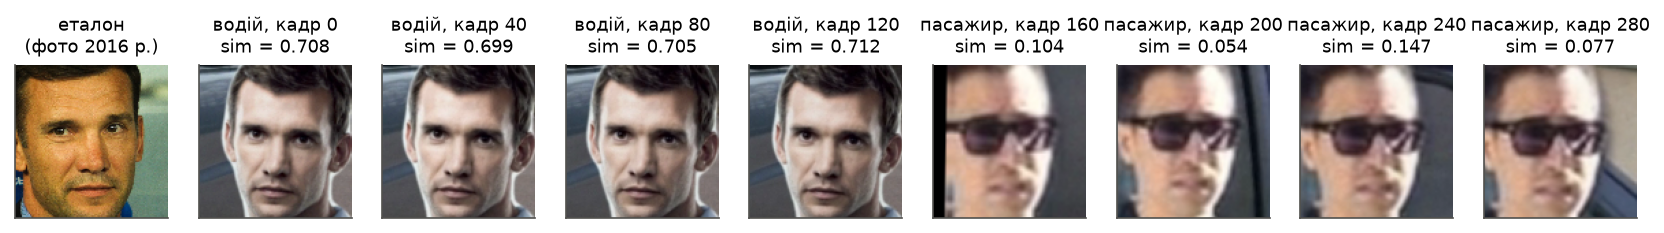

ВОДІЙ: трек #2, середня схожість 0.707 > 0.363


In [11]:
display(Image(str(C.FIGURES_DIR / "fig_similarity.png")))
display(Image(str(C.FIGURES_DIR / "fig_faces.png")))
print(f"ВОДІЙ: трек #{summary['driver_id']}, середня схожість {summary['driver_similarity']:.3f} > {C.SFACE_COSINE_THRESHOLD}")

## 5. Кількісна оцінка за еталонною розміткою

In [12]:
ev = result["evaluation"]
det = pd.DataFrame(ev["detection"]).T
det.index.name = "об'єкт"
display(det)
print("Номер:", {k: v for k, v in ev["plate"].items()})
print("Водій:", ev["driver"])
print("Рухомий об'єкт:", ev["moving"])

,frames_visible,recall_iou50,mean_iou,track_ids
об'єкт,,,,
car_main,1000,1.0,0.968,{1: 1000}
car_second,636,0.983,0.951,{4: 625}
driver,1000,0.864,0.96,{2: 864}
passenger,546,0.967,0.937,"{5: 495, 24: 33}"
dog,1000,0.994,0.945,{3: 994}


Номер: {'truth': 'KA7429MB', 'frames_analysed_plate_visible': 429, 'detection_rate': 1.0, 'valid_format_rate': 1.0, 'exact_read_rate': 1.0, 'vote_by_string': 'KA7429MB', 'vote_by_char': 'KA7429MB', 'final_correct': True}
Водій: {'predicted_track': 2, 'predicted_is': 'driver', 'correct': True, 'similarity': {'driver': {'mean': 0.707, 'min': 0.629, 'max': 0.746, 'n': 498}, 'passenger': {'mean': 0.115, 'min': 0.015, 'max': 0.726, 'n': 241}}}
Рухомий об'єкт: {'truth': 'passenger', 'predicted': ['passenger'], 'correct': True, 'naive_predicted': ['passenger'], 'naive_correct': True, 'naive_max_predicted': ['car_second', 'dog', 'passenger'], 'naive_max_correct': False}


## 6. Анотоване відео
Рамки з номерами треків, позначки `DRIVER` і `MOVING`, рамка номера з прочитаним текстом, обличчя зі схожістю,
траєкторія рухомого об'єкта (у координатах сцени, тому вона не «пливе» разом з камерою).

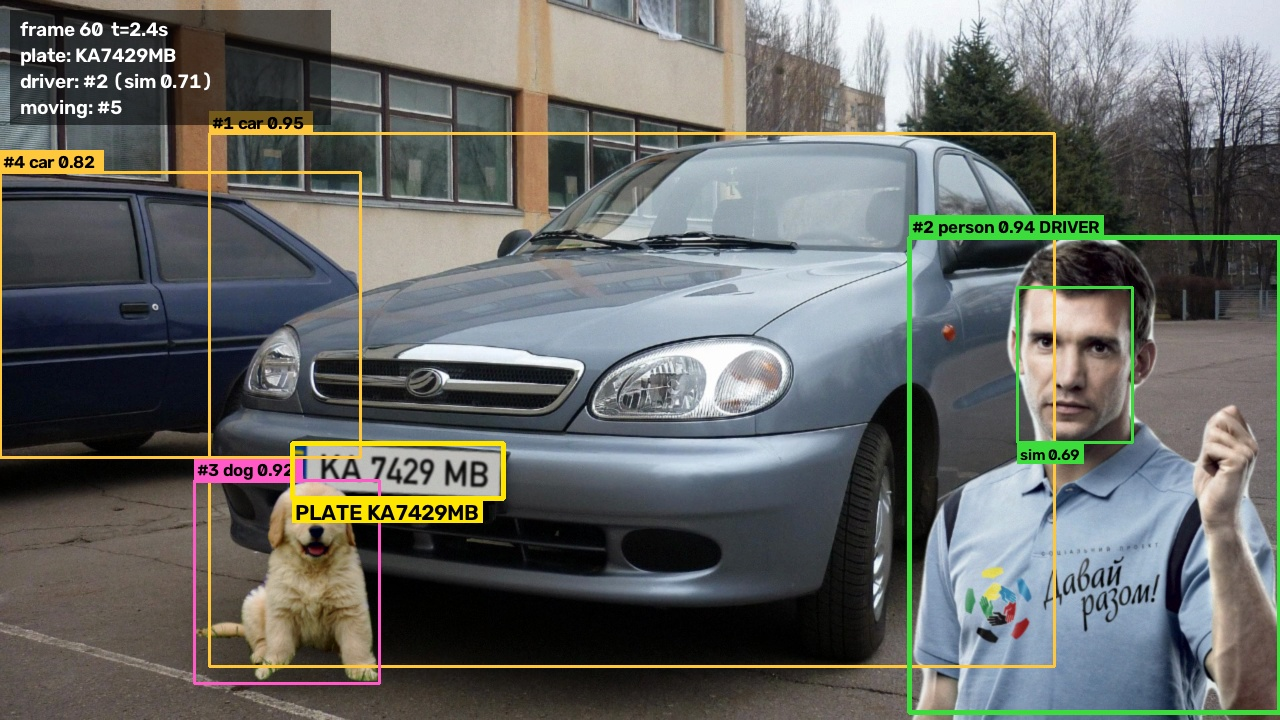

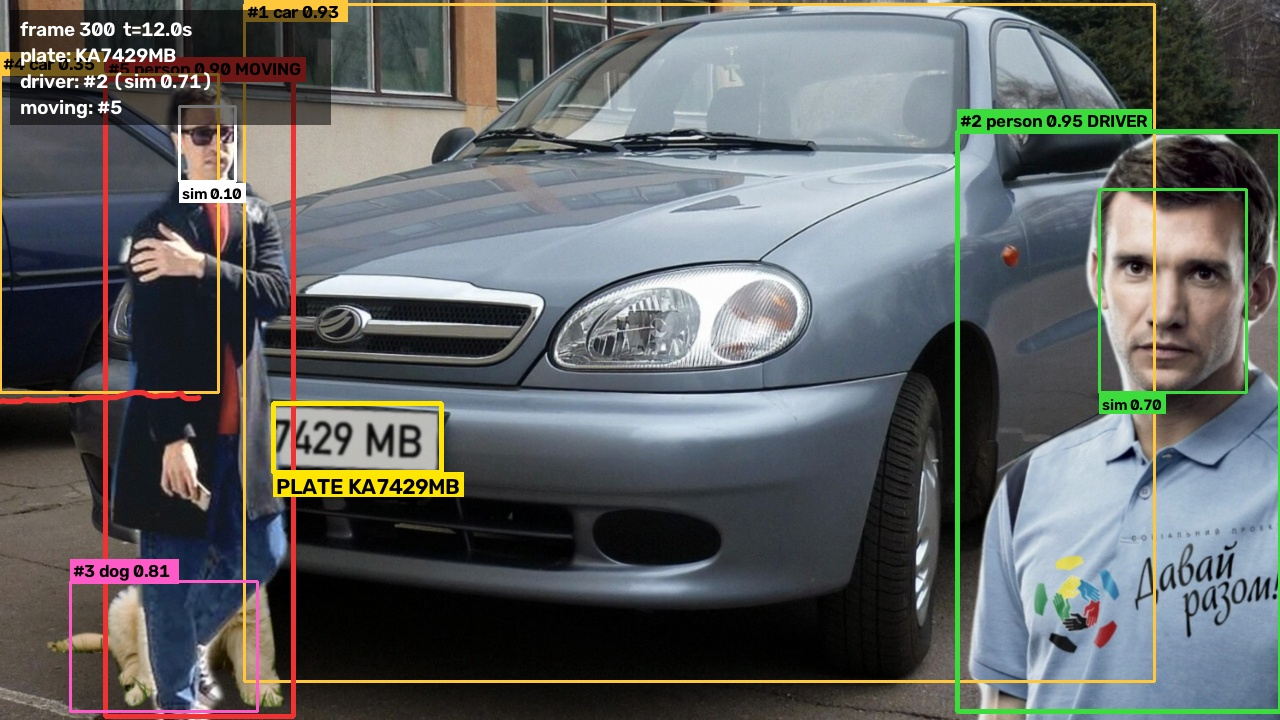

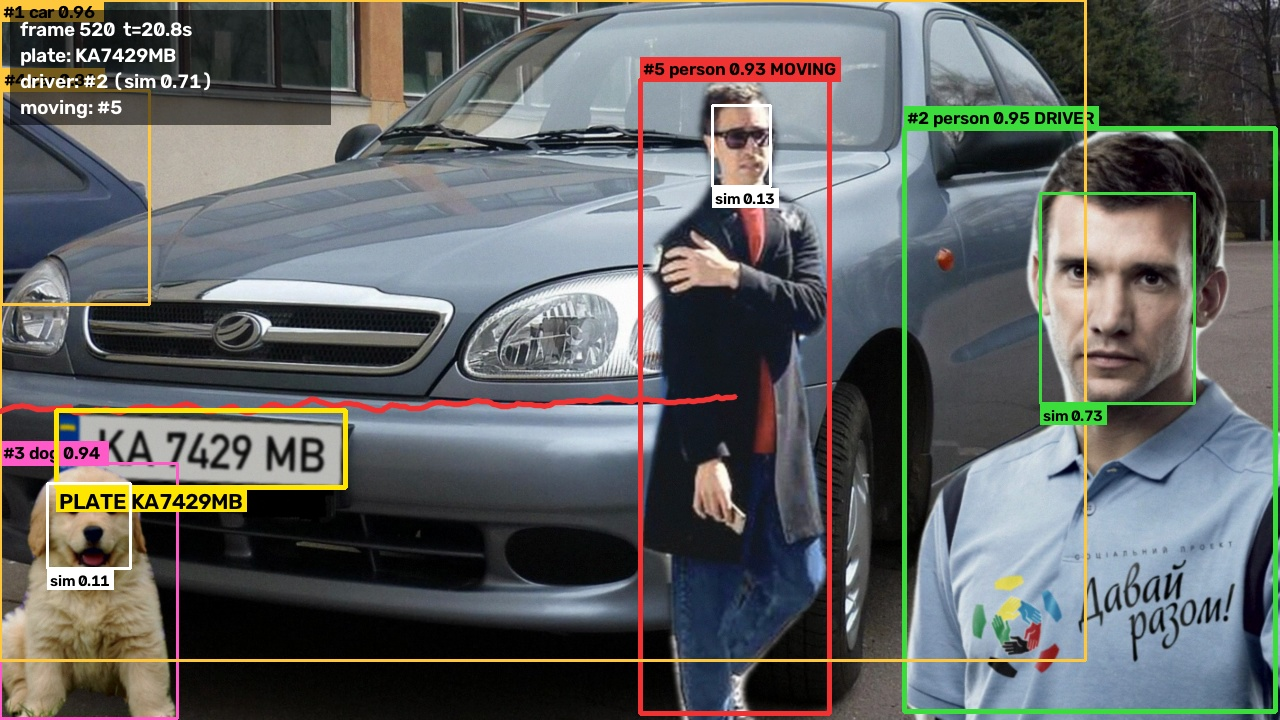

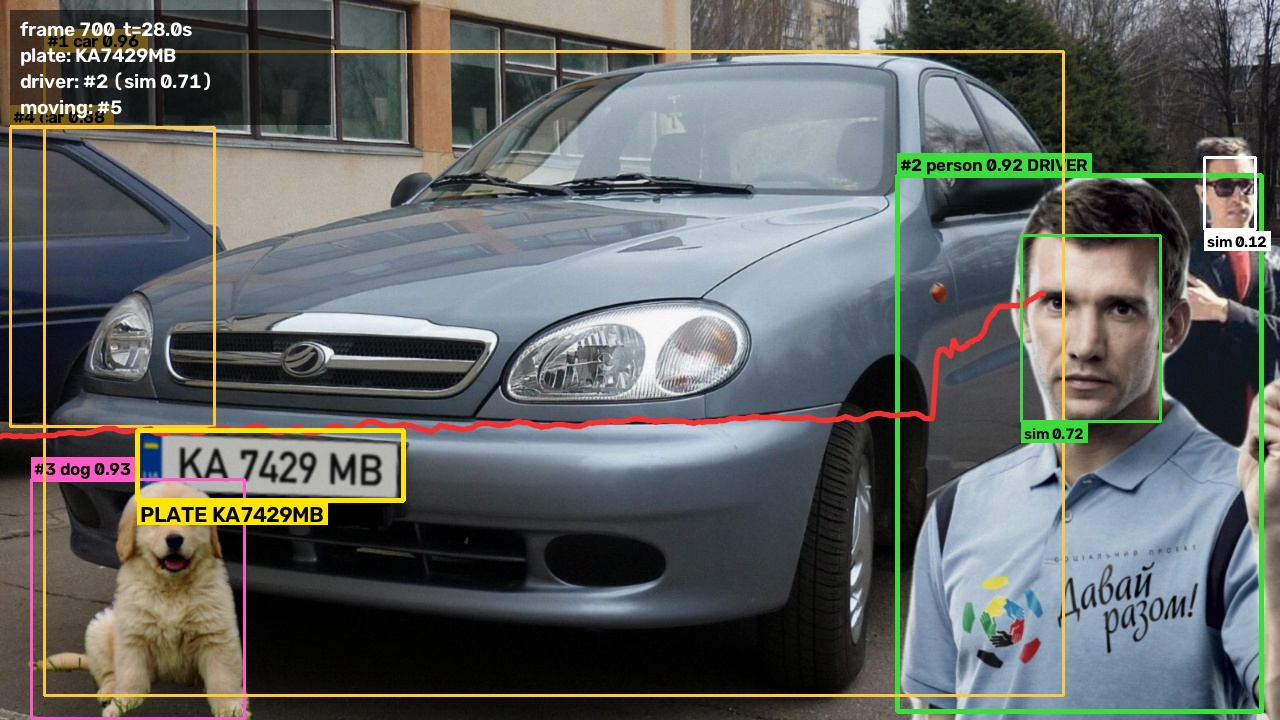

In [13]:
rel = Path("..") / C.ANNOTATED_VIDEO.relative_to(ROOT)
display(HTML(f'<video src="{rel}" width="860" controls muted></video>'))
for f in (60, 300, 520, 700):
    display(Image(str(C.FIGURES_DIR / f"annotated_{f:04d}.jpg"), width=860))

## 7. Підсумок

In [14]:
print(f"ПІДСУМОК ОБРОБКИ ВІДЕО {C.SCENE_VIDEO.name}\n" + "-" * 60)
print("Знайдені об'єкти:")
for t in summary["tracks"]:
    print(f"  #{t.track_id:<3} {t.cls:7} {'рухається' if t.moving else 'нерухомий':10} {t.role}")
print("Номер автомобіля:", summary["plate_text"])
print(f"Водій ідентифікований: {'так' if summary['driver_id'] else 'ні'} "
      f"(трек #{summary['driver_id']}, схожість {summary['driver_similarity']:.2f})")

ПІДСУМОК ОБРОБКИ ВІДЕО synthetic_scene.mp4
------------------------------------------------------------
Знайдені об'єкти:
  #1   car     нерухомий  автомобіль з номером KA7429MB
  #2   person  нерухомий  ВОДІЙ
  #3   dog     нерухомий  додатковий об'єкт
  #4   car     нерухомий  інший автомобіль
  #5   person  рухається  інша людина (пасажир)
Номер автомобіля: KA7429MB
Водій ідентифікований: так (трек #2, схожість 0.71)


**Висновки.** Конвеєр з відомих попередньо навчених мереж (YOLO11m + ByteTrack, YOLOv11-LP + EasyOCR,
YuNet + SFace) розв'язує всі пункти завдання на 40-секундному відео: виділено й розпізнано 5 об'єктів
(автомобіль з номером, другий автомобіль, водій, пасажир, собака), прочитано номер `KA7429MB` (100 % кадрів з
відкритим знаком), ідентифіковано водія (середня схожість ≈ 0.71 проти ≈ 0.12 для пасажира) і визначено
єдиний рухомий об'єкт — пасажира. Ключові інженерні рішення: компенсація руху камери, постобробка OCR за
шаблоном номера з голосуванням по кадрах, прийняття рішень по треку, а не по окремому кадру.